# Proyek Analisis Data: E-Commerce Public Dataset (Olist)
- **Nama:** Mila Sari Rusadi
- **Email:** 2002milasari@gmail.com
- **ID Dicoding:** mila_sari_rusadi_Jlfh

## Daftar Isi
1. Menentukan Pertanyaan Bisnis
2. Import Semua Packages/Library
3. Data Wrangling (Gathering, Assessing, Cleaning)
4. Exploratory Data Analysis (EDA)
5. Visualization & Explanatory Analysis
6. Analisis Lanjutan: RFM Analysis & Geospatial Analysis
7. Conclusion & Recommendation

## 1. Menentukan Pertanyaan Bisnis

Konteks: sebuah marketplace e-commerce Brasil ingin menentukan prioritas stok/promosi produk dan strategi retensi pelanggan. Seluruh pertanyaan memakai **pesanan berstatus `delivered`** pada periode **Januari 2017 – Agustus 2018** (periode bulan penuh; data 2016 dan setelah Agustus 2018 sangat sedikit sehingga bisa menyesatkan tren). Revenue didefinisikan sebagai jumlah `price` item (tanpa ongkir).

**Pertanyaan 1 (Produk)**
> Kategori produk apa saja yang menyumbang revenue tertinggi dan terendah selama Januari 2017 – Agustus 2018, dan bagaimana tren revenue bulanan 5 kategori teratas agar tim dapat menentukan kategori prioritas untuk stok dan promosi?

- *Specific*: revenue per kategori & tren bulanan top 5. *Measurable*: total revenue (BRL) dan persentase kontribusi. *Action-oriented*: prioritas stok/promosi. *Relevant*: kategori adalah dasar keputusan merchandising. *Time-bound*: Jan 2017 – Agu 2018.

**Pertanyaan 2 (Pelanggan & Wilayah)**
> Bagaimana sebaran pelanggan berdasarkan segmen RFM (Recency, Frequency, Monetary) dan berapa persen revenue yang disumbang tiap segmen serta tiap negara bagian pada Januari 2017 – Agustus 2018, agar tim dapat menentukan segmen dan wilayah yang diprioritaskan untuk kampanye retensi?

- *Specific*: segmen RFM & negara bagian. *Measurable*: jumlah pelanggan, % revenue, rata-rata recency/monetary. *Action-oriented*: menentukan target kampanye retensi. *Relevant*: retensi berdampak langsung pada pertumbuhan revenue. *Time-bound*: Jan 2017 – Agu 2018.

## 2. Import Semua Packages/Library

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
PRIMARY, GREY = '#1f5fa8', '#b8bec6'   # warna konsisten: biru = sorotan utama, abu = pembanding
pd.options.display.float_format = '{:,.2f}'.format

## 3. Data Wrangling
### 3.1 Gathering Data
Tahap ini memuat tabel-tabel yang diperlukan ke dalam DataFrame. `order_reviews` dan `sellers` tidak dipakai karena tidak berkaitan dengan kedua pertanyaan bisnis.

In [2]:
customers = pd.read_csv('data/customers_dataset.csv')
orders    = pd.read_csv('data/orders_dataset.csv')
items     = pd.read_csv('data/order_items_dataset.csv')
products  = pd.read_csv('data/products_dataset.csv')
category_tr = pd.read_csv('data/product_category_name_translation.csv')
geo       = pd.read_csv('data/geolocation_dataset.csv')

for name, d in [('customers', customers), ('orders', orders), ('order_items', items),
                ('products', products), ('category_translation', category_tr), ('geolocation', geo)]:
    print(f'{name:22s} {d.shape}')
orders.head()

customers              (99441, 5)
orders                 (99441, 8)
order_items            (112650, 7)
products               (32951, 9)
category_translation   (71, 2)
geolocation            (1000163, 5)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


**Insight (Gathering Data):**
- Terdapat 99.441 pesanan, 112.650 baris item pesanan, 99.441 baris pelanggan (`customer_id`), dan 32.951 produk.
- Tabel dihubungkan lewat `order_id` (orders ↔ items), `customer_id` (orders ↔ customers), dan `product_id` (items ↔ products). Nama kategori masih berbahasa Portugis sehingga perlu diterjemahkan dengan tabel `category_translation`.
- `customer_id` bersifat unik per pesanan; identitas pelanggan sebenarnya ada di `customer_unique_id` (penting untuk RFM).

### 3.2 Assessing Data
Memeriksa tipe data, missing value, duplikasi, dan outlier pada tiap tabel.

In [3]:
print('=== Tipe data orders ===')
print(orders.dtypes, end='\n\n')
print('=== Missing value ===')
for name, d in [('orders', orders), ('products', products), ('customers', customers), ('items', items)]:
    miss = d.isna().sum()
    print(name, '->', miss[miss > 0].to_dict() or 'tidak ada')

=== Tipe data orders ===
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

=== Missing value ===
orders -> {'order_approved_at': 160, 'order_delivered_carrier_date': 1783, 'order_delivered_customer_date': 2965}
products -> {'product_category_name': 610, 'product_name_lenght': 610, 'product_description_lenght': 610, 'product_photos_qty': 610, 'product_weight_g': 2, 'product_length_cm': 2, 'product_height_cm': 2, 'product_width_cm': 2}
customers -> tidak ada
items -> tidak ada


In [4]:
print('Duplikat baris:')
for name, d in [('customers', customers), ('orders', orders), ('items', items), ('products', products), ('geolocation', geo)]:
    print(f'  {name:12s}: {d.duplicated().sum():,}')

print('\nCustomer_id unik   :', customers.customer_id.nunique())
print('Customer_unique_id :', customers.customer_unique_id.nunique())
print('\nStatus pesanan:'); print(orders.order_status.value_counts())
print('\nRentang tanggal pembelian:', orders.order_purchase_timestamp.min(), 's/d', orders.order_purchase_timestamp.max())

Duplikat baris:
  customers   : 0
  orders      : 0


  items       : 0


  products    : 0


  geolocation : 261,831

Customer_id unik   : 99441
Customer_unique_id : 96096

Status pesanan:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Rentang tanggal pembelian: 2016-09-04 21:15:19 s/d 2018-10-17 17:30:18


In [5]:
# Kategori produk yang tidak punya terjemahan & distribusi harga (outlier)
tmp = products.merge(category_tr, on='product_category_name', how='left')
print('Kategori tanpa terjemahan:', tmp[tmp.product_category_name_english.isna() & tmp.product_category_name.notna()].product_category_name.unique().tolist())
print()
print(items[['price', 'freight_value']].describe())
print('\nItem dengan harga > 3000 :', (items.price > 3000).sum())

Kategori tanpa terjemahan: ['pc_gamer', 'portateis_cozinha_e_preparadores_de_alimentos']

           price  freight_value
count 112,650.00     112,650.00
mean      120.65          19.99
std       183.63          15.81
min         0.85           0.00
25%        39.90          13.08
50%        74.99          16.26
75%       134.90          21.15
max     6,735.00         409.68

Item dengan harga > 3000 : 25


**Insight (Assessing Data):**
1. **Missing value**
   - `orders`: `order_approved_at` (160), `order_delivered_carrier_date` (1.783), dan `order_delivered_customer_date` (2.965) kosong, terutama pada pesanan yang belum terkirim/dibatalkan. Kolom ini tidak dipakai pada analisis, dan pesanan tersebut tersaring saat kita hanya memakai status `delivered`.
   - `products`: 610 produk tidak memiliki kategori. Produk ini akan diberi label `unknown`.
2. **Duplicate data**: `geolocation` memiliki 261.831 baris duplikat. Perlu `drop_duplicates()` agar rata-rata koordinat per negara bagian tidak bias oleh titik yang berulang.
3. **Inconsistent value**: dua kategori (`pc_gamer`, `portateis_cozinha_e_preparadores_de_alimentos`) tidak ada di tabel terjemahan, dan `customer_id` berbeda untuk pelanggan yang sama (`customer_unique_id` hanya 96.096 dari 99.441). Solusi: pakai nama Portugis untuk kategori tanpa terjemahan, dan pakai `customer_unique_id` untuk analisis pelanggan.
4. **Invalid value / tipe data**: kolom tanggal masih bertipe teks (string) sehingga harus dikonversi ke `datetime`.
5. **Outlier**: harga item sangat skewed (median ~75, maksimum 6.735). Outlier dibiarkan karena merupakan transaksi valid (produk mahal), tetapi akan dibahas saat interpretasi agar tidak menyesatkan.
6. **Cakupan waktu**: 2016 dan September–Oktober 2018 hanya berisi sedikit pesanan, sehingga analisis dibatasi pada Jan 2017 – Agu 2018.

### 3.3 Cleaning Data
Menerapkan solusi dari tahap Assessing Data, lalu menggabungkan tabel menjadi satu dataset analisis.

In [6]:
# 1) Konversi tipe data tanggal
orders['order_purchase_timestamp'] = pd.to_datetime(orders['order_purchase_timestamp'])

# 2) Hapus duplikat geolocation
geo = geo.drop_duplicates()

# 3) Terjemahkan kategori; fallback ke nama Portugis, lalu 'unknown' untuk yang kosong
products = products.merge(category_tr, on='product_category_name', how='left')
products['category'] = (products['product_category_name_english']
                        .fillna(products['product_category_name'])
                        .fillna('unknown'))

# 4) Gabungkan tabel & filter: hanya pesanan delivered pada Jan 2017 - Agu 2018
df = (items
      .merge(orders[['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp']], on='order_id')
      .merge(customers[['customer_id', 'customer_unique_id', 'customer_state']], on='customer_id')
      .merge(products[['product_id', 'category']], on='product_id', how='left'))

df = df[(df.order_status == 'delivered')
        & (df.order_purchase_timestamp >= '2017-01-01')
        & (df.order_purchase_timestamp < '2018-09-01')].copy()
df['category'] = df['category'].fillna('unknown')
df['year_month'] = df.order_purchase_timestamp.dt.to_period('M')

print('Shape dataset analisis :', df.shape)
print('Duplikat geolocation tersisa:', geo.duplicated().sum())
print('Missing value:', df[['price', 'category', 'customer_state', 'customer_unique_id']].isna().sum().sum())
df.head()

Shape dataset analisis : (109880, 14)


Duplikat geolocation tersisa: 0
Missing value: 0


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,customer_id,order_status,order_purchase_timestamp,customer_unique_id,customer_state,category,year_month
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,3ce436f183e68e07877b285a838db11a,delivered,2017-09-13 08:59:02,871766c5855e863f6eccc05f988b23cb,RJ,cool_stuff,2017-09
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,f6dd3ec061db4e3987629fe6b26e5cce,delivered,2017-04-26 10:53:06,eb28e67c4c0b83846050ddfb8a35d051,SP,pet_shop,2017-04
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,6489ae5e4333f3693df5ad4372dab6d3,delivered,2018-01-14 14:33:31,3818d81c6709e39d06b2738a8d3a2474,MG,furniture_decor,2018-01
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,d4eb9395c8c0431ee92fce09860c5a06,delivered,2018-08-08 10:00:35,af861d436cfc08b2c2ddefd0ba074622,SP,perfumery,2018-08
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,58dbd0b2d70206bf40e62cd34e84d795,delivered,2017-02-04 13:57:51,64b576fb70d441e8f1b2d7d446e483c5,SP,garden_tools,2017-02


**Insight (Cleaning Data):**
- Setelah difilter, tersisa **109.880 baris item** dari pesanan `delivered` Jan 2017 – Agu 2018 dengan total revenue sekitar **BRL 13,18 juta**.
- Tidak ada missing value pada kolom yang dipakai, kategori sudah dalam bahasa Inggris, dan duplikasi geolocation sudah dihapus.

## 4. Exploratory Data Analysis (EDA)
### 4.1 Pertanyaan 1: Revenue per kategori

In [7]:
cat_rev = (df.groupby('category')
             .agg(revenue=('price', 'sum'), items_sold=('order_id', 'count'))
             .sort_values('revenue', ascending=False))
cat_rev['pct_revenue'] = cat_rev.revenue / cat_rev.revenue.sum() * 100
print('Jumlah kategori:', len(cat_rev))
print('Kontribusi top-5 kategori: %.1f%%' % cat_rev.pct_revenue.head(5).sum())
print('Kontribusi top-10 kategori: %.1f%%' % cat_rev.pct_revenue.head(10).sum())
print('\nTop 10'); display(cat_rev.head(10))
print('Bottom 5'); display(cat_rev.tail(5))

Jumlah kategori: 74
Kontribusi top-5 kategori: 39.9%
Kontribusi top-10 kategori: 62.5%

Top 10


,revenue,items_sold,pct_revenue
category,,,
health_beauty,"1,229,557.50",9422,9.33
watches_gifts,"1,163,465.91",5855,8.83
bed_bath_table,"1,022,955.77",10945,7.76
sports_leisure,"952,840.40",8414,7.23
computers_accessories,"888,055.59",7632,6.74
furniture_decor,"706,237.17",8095,5.36
housewares,"614,341.62",6783,4.66
cool_stuff,"609,158.00",3711,4.62
auto,"577,838.39",4132,4.38


Bottom 5


,revenue,items_sold,pct_revenue
category,,,
flowers,"1,110.04",33,0.01
home_comfort_2,760.27,30,0.01
cds_dvds_musicals,730.00,14,0.01
fashion_childrens_clothes,519.95,7,0.00
security_and_services,283.29,2,0.00


In [8]:
top5 = cat_rev.head(5).index.tolist()
monthly_top5 = (df[df.category.isin(top5)]
                  .pivot_table(index='year_month', columns='category', values='price', aggfunc='sum')[top5])
total_month = df.groupby('year_month').price.sum()
print('Bulan revenue tertinggi:', total_month.idxmax(), '-> BRL {:,.0f}'.format(total_month.max()))
print('\nBulan puncak per kategori top 5:'); print(monthly_top5.idxmax())
q1 = monthly_top5.loc['2018-01':'2018-03'].sum(); q3 = monthly_top5.loc['2018-06':'2018-08'].sum()
print('\nPerubahan revenue (Jan-Mar 2018 -> Jun-Agu 2018):')
print(((q3 / q1 - 1) * 100).round(1).astype(str) + ' %')

Bulan revenue tertinggi: 2017-11 -> BRL 987,765

Bulan puncak per kategori top 5:
category
health_beauty            2018-08
watches_gifts            2018-05
bed_bath_table           2017-11
sports_leisure           2018-01
computers_accessories    2018-02
dtype: period[M]

Perubahan revenue (Jan-Mar 2018 -> Jun-Agu 2018):
category
health_beauty             37.1 %
watches_gifts              8.7 %
bed_bath_table            -8.6 %
sports_leisure           -38.2 %
computers_accessories    -53.7 %
dtype: str


**Insight (EDA Pertanyaan 1):**
- Dari 74 kategori (termasuk `unknown`), **5 kategori teratas** (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`) menyumbang **39,9%** revenue, dan 10 teratas menyumbang **62,5%**. Kategori terendah (mis. `security_and_services`, `fashion_childrens_clothes`, `cds_dvds_musicals`) hanya bernilai ratusan BRL.
- Revenue bulanan total puncak pada **November 2017 (≈BRL 988 ribu)**, bertepatan dengan musim Black Friday.
- Membandingkan Jan–Mar 2018 dengan Jun–Agu 2018: `health_beauty` naik sekitar **+37%** dan `watches_gifts` **+9%**, sedangkan `bed_bath_table` (−9%), `sports_leisure` (−38%), dan terutama `computers_accessories` (**−54%**) menurun.

### 4.2 Pertanyaan 2: Pelanggan (RFM) dan negara bagian

In [9]:
snapshot = df.order_purchase_timestamp.max().normalize() + pd.Timedelta(days=1)

rfm = (df.groupby('customer_unique_id')
         .agg(last_purchase=('order_purchase_timestamp', 'max'),
              frequency=('order_id', 'nunique'),
              monetary=('price', 'sum'))
         .reset_index())
rfm['recency'] = (snapshot - rfm.last_purchase).dt.days

print('Tanggal acuan (snapshot):', snapshot.date())
print('Jumlah pelanggan unik  :', len(rfm))
print('\nDistribusi frequency:'); print(rfm.frequency.value_counts().sort_index().head(6))
rfm[['recency', 'frequency', 'monetary']].describe()

Tanggal acuan (snapshot): 2018-08-30
Jumlah pelanggan unik  : 93104

Distribusi frequency:
frequency
1    90315
2     2562
3      180
4       28
5        9
6        5
Name: count, dtype: int64


,recency,frequency,monetary
count,"93,104.00","93,104.00","93,104.00"
mean,236.24,1.03,141.57
std,150.95,0.21,215.76
min,0.00,1.00,0.85
25%,114.00,1.00,47.65
50%,218.00,1.00,89.70
75%,345.00,1.00,154.17
max,601.00,15.00,"13,440.00"


**Teknik analisis (RFM Analysis):** mengelompokkan pelanggan berdasarkan *Recency* (hari sejak pembelian terakhir), *Frequency* (jumlah pesanan unik), dan *Monetary* (total belanja). Karena ±97% pelanggan hanya membeli sekali, skor frequency tidak cocok dibuat kuantil; kita pakai **binning manual** (`pd.cut`: 1, 2, ≥3 pesanan), sedangkan Recency dan Monetary memakai kuantil (`pd.qcut`) skor 1–5. Segmen kemudian ditetapkan dengan aturan bisnis (manual grouping).

In [10]:
rfm['R'] = pd.qcut(rfm.recency.rank(method='first'), 5, labels=[5, 4, 3, 2, 1]).astype(int)   # recency kecil = skor tinggi
rfm['F'] = pd.cut(rfm.frequency, bins=[0, 1, 2, np.inf], labels=[1, 3, 5]).astype(int)
rfm['M'] = pd.qcut(rfm.monetary.rank(method='first'), 5, labels=[1, 2, 3, 4, 5]).astype(int)

def assign_segment(r):
    if r.frequency >= 2 and r.R >= 4: return 'Champions'          # sering beli & baru-baru ini
    if r.frequency >= 2:              return 'Loyal'              # sering beli, tidak baru
    if r.M == 5:                      return 'Big Spenders'       # sekali beli, nilai besar
    if r.R >= 4:                      return 'New/Recent'         # sekali beli, baru
    if r.R <= 2:                      return 'Lost/Hibernating'   # sekali beli, sudah lama
    return 'Average'

rfm['segment'] = rfm.apply(assign_segment, axis=1)

seg = (rfm.groupby('segment')
          .agg(customers=('customer_unique_id', 'count'), revenue=('monetary', 'sum'),
               avg_recency=('recency', 'mean'), avg_monetary=('monetary', 'mean')))
seg['pct_customers'] = seg.customers / seg.customers.sum() * 100
seg['pct_revenue'] = seg.revenue / seg.revenue.sum() * 100
seg = seg.sort_values('pct_revenue', ascending=False)
seg

,customers,revenue,avg_recency,avg_monetary,pct_customers,pct_revenue
segment,,,,,,
Big Spenders,17207,"6,888,433.12",238.98,400.33,18.48,52.26
New/Recent,29165,"2,249,452.82",89.44,77.13,31.33,17.07
Lost/Hibernating,29214,"2,191,747.25",391.61,75.02,31.38,16.63
Average,14729,"1,126,038.90",218.80,76.45,15.82,8.54
Loyal,1592,"401,143.56",317.72,251.97,1.71,3.04
Champions,1197,"324,211.48",87.97,270.85,1.29,2.46


In [11]:
state_rev = (df.groupby('customer_state')
               .agg(revenue=('price', 'sum'), customers=('customer_unique_id', 'nunique'))
               .sort_values('revenue', ascending=False))
state_rev['pct_revenue'] = state_rev.revenue / state_rev.revenue.sum() * 100
state_rev['revenue_per_customer'] = state_rev.revenue / state_rev.customers
print('Jumlah negara bagian:', len(state_rev))
print('Kontribusi 3 negara bagian teratas: %.1f%%' % state_rev.pct_revenue.head(3).sum())
state_rev.head(8)

Jumlah negara bagian: 27
Kontribusi 3 negara bagian teratas: 63.4%


,revenue,customers,pct_revenue,revenue_per_customer
customer_state,,,,
SP,"5,055,587.13",39065,38.36,129.41
RJ,"1,751,433.85",11879,13.29,147.44
MG,"1,548,206.88",10969,11.75,141.14
RS,"726,373.92",5151,5.51,141.02
PR,"664,048.00",4750,5.04,139.80
SC,"504,774.07",3441,3.83,146.69
BA,"493,339.26",3155,3.74,156.37
DF,"295,454.64",2013,2.24,146.77


**Insight (EDA Pertanyaan 2):**
- Dari **93.104 pelanggan** unik, 97% hanya membeli satu kali; hanya sekitar **3%** (segmen *Champions* + *Loyal*) yang membeli ≥ 2 kali.
- Segmen **Big Spenders** hanya **18,5%** pelanggan, tetapi menghasilkan **52,3%** revenue (rata-rata BRL 400 per pelanggan). Segmen **Lost/Hibernating** (31,4% pelanggan, rata-rata 392 hari sejak pembelian terakhir) dan **New/Recent** (31,3%) menyumbang masing-masing 16,6% dan 17,1% revenue.
- Pada level wilayah, **SP, RJ, dan MG** menyumbang **63,4%** revenue; **SP sendiri 38,4%**. Di 8 negara bagian teratas, rata-rata belanja per pelanggan relatif seragam (BRL 129–156), sehingga perbedaan revenue lebih ditentukan oleh *jumlah pelanggan*, bukan nilai belanja.

## 5. Visualization & Explanatory Analysis
### Pertanyaan 1: Kategori produk dengan revenue tertinggi/terendah dan tren bulanan top 5

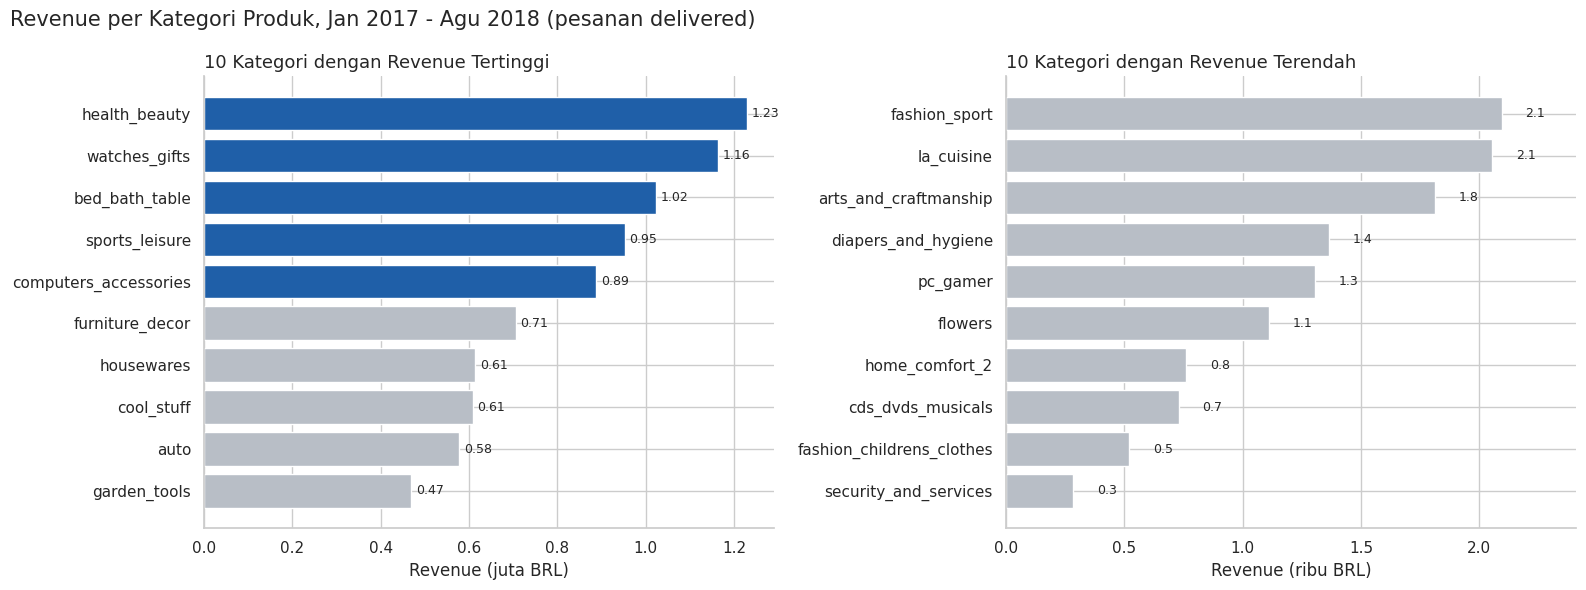

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
top10 = cat_rev.head(10).iloc[::-1]
colors_top = [PRIMARY if i >= 5 else GREY for i in range(10)]   # sorot 5 teratas
axes[0].barh(top10.index, top10.revenue / 1e6, color=colors_top)
axes[0].set_title('10 Kategori dengan Revenue Tertinggi', fontsize=13, loc='left')
axes[0].set_xlabel('Revenue (juta BRL)')
for i, v in enumerate(top10.revenue / 1e6):
    axes[0].text(v + 0.01, i, f'{v:.2f}', va='center', fontsize=9)

bot10 = cat_rev.tail(10).iloc[::-1]
axes[1].barh(bot10.index, bot10.revenue / 1e3, color=GREY)
axes[1].set_title('10 Kategori dengan Revenue Terendah', fontsize=13, loc='left')
axes[1].set_xlabel('Revenue (ribu BRL)'); axes[1].set_xlim(0, bot10.revenue.max() / 1e3 * 1.15)
for i, v in enumerate(bot10.revenue / 1e3):
    axes[1].text(v + 0.1, i, f'{v:.1f}', va='center', fontsize=9)
fig.suptitle('Revenue per Kategori Produk, Jan 2017 - Agu 2018 (pesanan delivered)', fontsize=15, x=0.01, ha='left')
sns.despine(); plt.tight_layout(); plt.show()

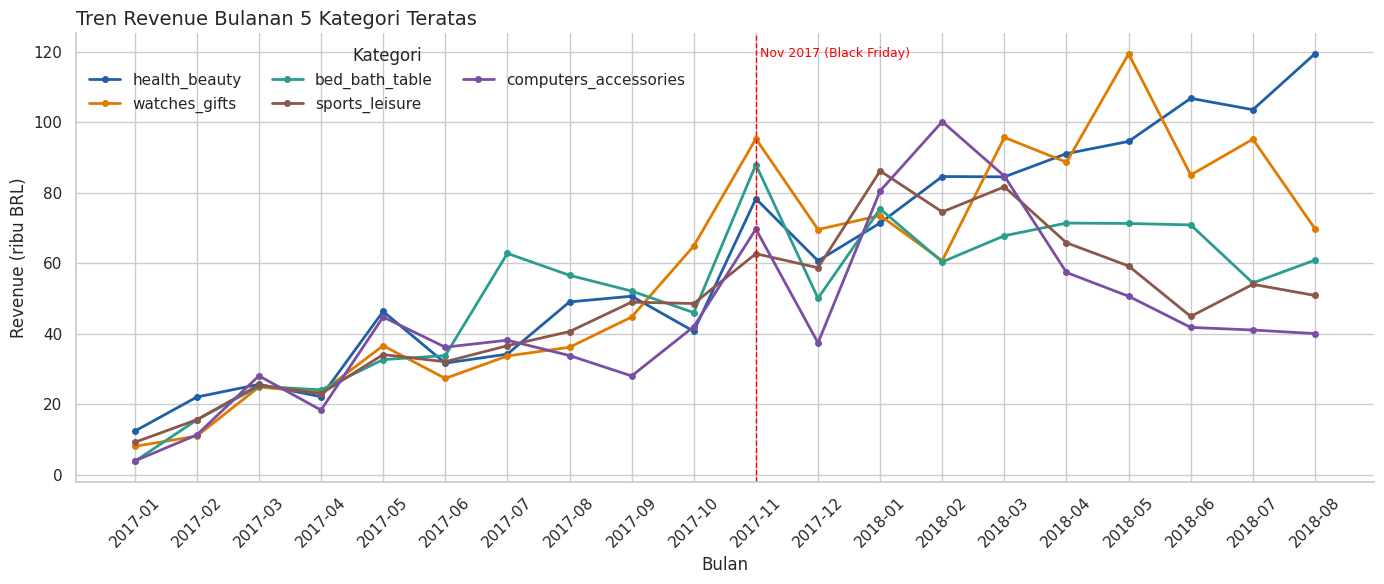

In [13]:
fig, ax = plt.subplots(figsize=(14, 6))
palette = ['#1f5fa8', '#e07b00', '#2a9d8f', '#8c564b', '#7a4fa3']
for col, c in zip(top5, palette):
    ax.plot(monthly_top5.index.astype(str), monthly_top5[col] / 1e3, marker='o', ms=4, lw=2, label=col, color=c)
ax.axvline('2017-11', color='red', ls='--', lw=1)
ax.text('2017-11', ax.get_ylim()[1] * 0.97, ' Nov 2017 (Black Friday)', color='red', fontsize=9, va='top')
ax.set_title('Tren Revenue Bulanan 5 Kategori Teratas', fontsize=14, loc='left')
ax.set_xlabel('Bulan'); ax.set_ylabel('Revenue (ribu BRL)')
plt.xticks(rotation=45); ax.legend(title='Kategori', ncol=3, loc='upper left', frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

**Penjelasan visualisasi 1:** Bar chart membandingkan kontribusi revenue per kategori (biru = 5 teratas), dan line chart menunjukkan dinamika bulanannya. Skala sumbu pada panel kanan sengaja berbeda (ribu BRL) karena nilai kategori terendah jauh lebih kecil, sehingga perlu dibaca dengan memperhatikan satuannya.

### Pertanyaan 2: Segmen RFM dan negara bagian

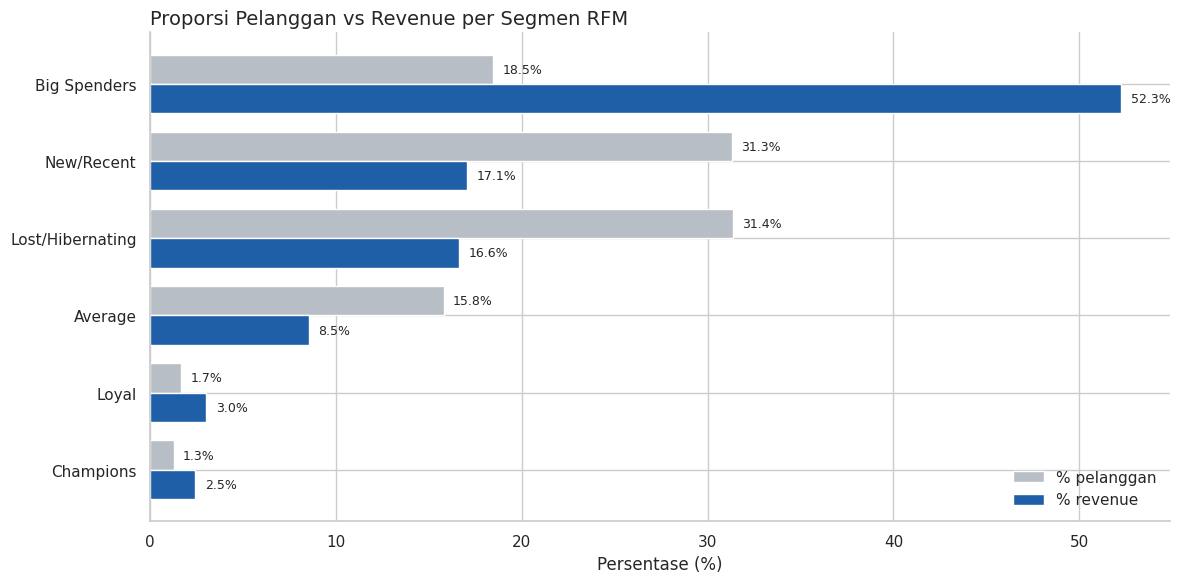

In [14]:
order = seg.sort_values('pct_revenue', ascending=True).index
x = seg.loc[order]
fig, ax = plt.subplots(figsize=(12, 6))
y = np.arange(len(x)); h = 0.38
ax.barh(y + h/2, x.pct_customers, height=h, color=GREY, label='% pelanggan')
ax.barh(y - h/2, x.pct_revenue, height=h, color=PRIMARY, label='% revenue')
ax.set_yticks(y); ax.set_yticklabels(x.index)
for i, (a, b) in enumerate(zip(x.pct_customers, x.pct_revenue)):
    ax.text(a + 0.5, i + h/2, f'{a:.1f}%', va='center', fontsize=9)
    ax.text(b + 0.5, i - h/2, f'{b:.1f}%', va='center', fontsize=9)
ax.set_title('Proporsi Pelanggan vs Revenue per Segmen RFM', fontsize=14, loc='left')
ax.set_xlabel('Persentase (%)'); ax.legend(frameon=False)
sns.despine(); plt.tight_layout(); plt.show()

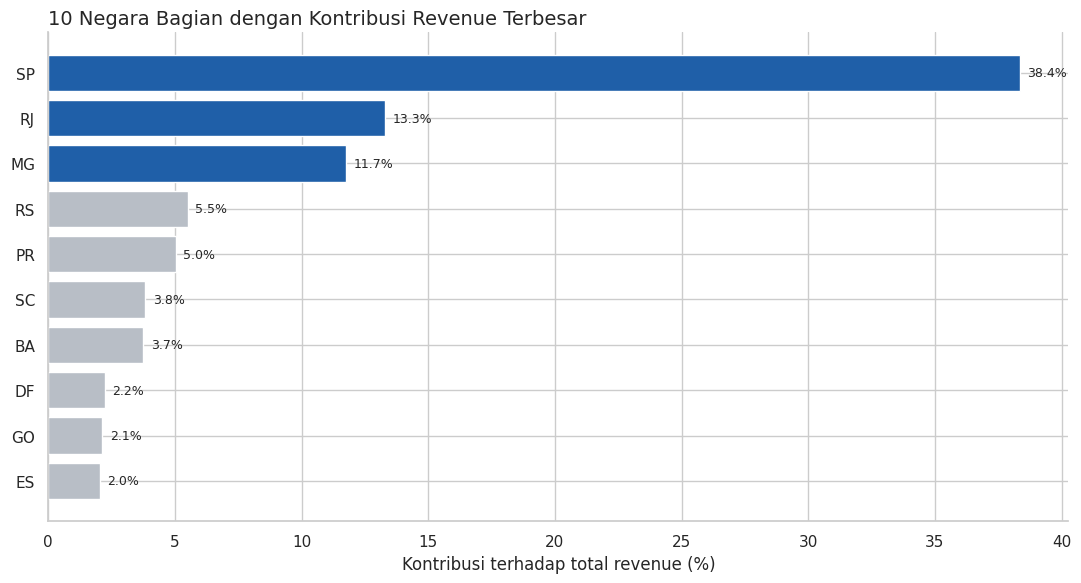

In [15]:
top_state = state_rev.head(10).iloc[::-1]
colors_state = [PRIMARY if i >= 7 else GREY for i in range(10)]
fig, ax = plt.subplots(figsize=(11, 6))
ax.barh(top_state.index, top_state.pct_revenue, color=colors_state)
for i, v in enumerate(top_state.pct_revenue):
    ax.text(v + 0.3, i, f'{v:.1f}%', va='center', fontsize=9)
ax.set_title('10 Negara Bagian dengan Kontribusi Revenue Terbesar', fontsize=14, loc='left')
ax.set_xlabel('Kontribusi terhadap total revenue (%)')
sns.despine(); plt.tight_layout(); plt.show()

## 6. Analisis Lanjutan
### 6.1 RFM Analysis
RFM Analysis sudah diterapkan pada bagian 4.2 dan divisualisasikan pada bagian 5 (pembahasan Pertanyaan 2). Berikut ringkasan profil tiap segmen.

In [16]:
seg[['customers', 'pct_customers', 'pct_revenue', 'avg_recency', 'avg_monetary']].round(1)

,customers,pct_customers,pct_revenue,avg_recency,avg_monetary
segment,,,,,
Big Spenders,17207,18.50,52.30,239.00,400.30
New/Recent,29165,31.30,17.10,89.40,77.10
Lost/Hibernating,29214,31.40,16.60,391.60,75.00
Average,14729,15.80,8.50,218.80,76.50
Loyal,1592,1.70,3.00,317.70,252.00
Champions,1197,1.30,2.50,88.00,270.90


### 6.2 Geospatial Analysis
Tujuan: melihat pola geografis revenue. Koordinat tiap negara bagian dihitung dari rata-rata `geolocation_lat/lng` (setelah duplikat dihapus), lalu dipetakan sebagai bubble: **ukuran = revenue**, **warna = revenue per pelanggan**.

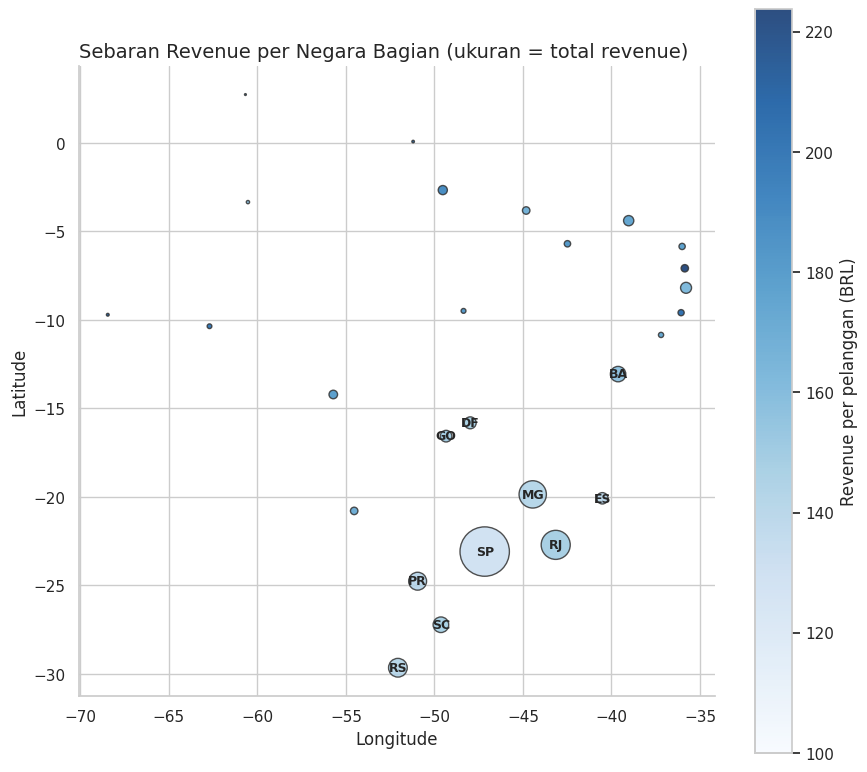

In [17]:
geo_state = geo.groupby('geolocation_state').agg(lat=('geolocation_lat', 'mean'), lng=('geolocation_lng', 'mean')).reset_index()
geo_map = state_rev.reset_index().merge(geo_state, left_on='customer_state', right_on='geolocation_state')

fig, ax = plt.subplots(figsize=(9, 8))
sc = ax.scatter(geo_map.lng, geo_map.lat, s=geo_map.revenue / 4000, c=geo_map.revenue_per_customer,
                cmap='Blues', edgecolor='#333', alpha=0.85, vmin=100)
for _, r in geo_map.iterrows():
    if r.pct_revenue > 2:
        ax.annotate(r.customer_state, (r.lng, r.lat), ha='center', va='center', fontsize=9, fontweight='bold')
cb = plt.colorbar(sc); cb.set_label('Revenue per pelanggan (BRL)')
ax.set_title('Sebaran Revenue per Negara Bagian (ukuran = total revenue)', fontsize=14, loc='left')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude'); ax.set_aspect('equal')
sns.despine(); plt.tight_layout(); plt.show()

**Insight (Geospatial):** revenue sangat terpusat di wilayah tenggara Brasil (SP, RJ, MG) dan selatan (RS, PR, SC). Wilayah utara dan timur laut berukuran kecil namun revenue per pelanggannya tidak lebih rendah (mis. BA ≈ BRL 156), sehingga rendahnya revenue di sana lebih mungkin disebabkan oleh **jumlah pelanggan yang sedikit**, bukan daya beli.

## 7. Conclusion & Recommendation

### Kesimpulan Pertanyaan 1 (Kategori produk)
- Revenue terkonsentrasi pada **5 kategori teratas** (`health_beauty`, `watches_gifts`, `bed_bath_table`, `sports_leisure`, `computers_accessories`) dengan kontribusi **±39,9%** dari total revenue (BRL 13,18 juta). Kategori terendah (mis. `security_and_services`, `fashion_childrens_clothes`) praktis tidak berkontribusi.
- Revenue bulanan mencapai puncak pada **November 2017**. Pada pertengahan 2018, `health_beauty` (+37%) dan `watches_gifts` (+9%) tumbuh, sementara `computers_accessories` turun sekitar 54% dibanding awal 2018.

### Kesimpulan Pertanyaan 2 (Pelanggan dan wilayah)
- Sekitar 97% pelanggan hanya membeli sekali. Segmen **Big Spenders (18,5% pelanggan)** menghasilkan **52,3% revenue**, sedangkan *Champions + Loyal* hanya ±3% pelanggan.
- **SP, RJ, dan MG** menyumbang **63,4%** revenue (SP saja 38,4%). Nilai belanja per pelanggan relatif merata antar wilayah, sehingga ekspansi pelanggan di wilayah lain berpotensi menambah revenue.

### Rekomendasi (Action Item)
1. **Prioritaskan stok dan promosi** pada 5 kategori teratas, terutama `health_beauty` dan `watches_gifts` yang masih tumbuh; siapkan kampanye dan stok ekstra menjelang **Black Friday (November)**.
2. **Selidiki penurunan `computers_accessories`** (kompetisi harga, stok, atau kualitas seller) sebelum menambah anggaran promosinya.
3. **Program retensi untuk Big Spenders** (VIP/penawaran personal) agar mereka melakukan pembelian ulang, serta **kampanye reaktivasi** (voucher/email) untuk segmen *Lost/Hibernating* dan *New/Recent* guna menaikkan jumlah pelanggan repeat.
4. **Pertahankan SP, RJ, MG** dan uji **akuisisi pelanggan** (promo ongkir/iklan lokal) di wilayah dengan revenue per pelanggan tinggi tetapi basis pelanggan kecil seperti BA, SC, dan DF.

## Menyimpan Data untuk Dashboard

In [18]:
import os
os.makedirs('dashboard', exist_ok=True)
main_data = df[['order_id', 'customer_unique_id', 'customer_state', 'order_purchase_timestamp', 'category', 'price']]
main_data.to_csv('dashboard/main_data.csv', index=False)
geo_state.to_csv('dashboard/state_geo.csv', index=False)
print(main_data.shape)

(109880, 6)
